# Differential equations 3: Second-order equations, oscillations and resonance

*Learning path: differential equations, part 3 of 8.* [Index](README.md) · Previous: [Linear first-order equations](02-linear-first-order.ipynb) · Next: [Laplace transforms](04-laplace-transforms.ipynb)

In 1940 the Tacoma Narrows bridge twisted itself apart in a steady wind. Soldiers break step when they cross a bridge.
A singer can shatter a glass. All three are about **resonance**: a system that likes to oscillate at one frequency,
pushed at that frequency. Newton's law $F = ma$ makes mechanics a story of second derivatives, and the equation of a
mass on a spring with a damper,

$$m\,y'' + c\,y' + k\,y = F(t),$$

is the model behind car suspensions, electrical circuits, buildings in earthquakes and atoms absorbing light. This
lesson solves it completely.

**Who this is for.** You have done [lessons 1 and 2](01-first-order-equations.ipynb) and know complex numbers and
Euler's formula $e^{i\theta} = \cos\theta + i\sin\theta$ ([foundations 6](../foundations/06-complex-numbers.ipynb)).

**What you will be able to do afterwards:**

1. solve $ay'' + by' + cy = 0$ from the roots of the characteristic equation, in all three cases;
2. classify a damped oscillator as underdamped, critically damped or overdamped;
3. find a particular solution by undetermined coefficients, including the resonant case;
4. compute the amplitude response of a driven oscillator and locate its peak;
5. solve a Cauchy–Euler equation $x^2y'' + bxy' + cy = 0$.

Plan about an hour and a half.

## 1. The characteristic equation

For $y'' - 5y' + 6y = 0$, try $y = e^{rt}$ as in lesson 1. Then $y' = re^{rt}$ and $y'' = r^2e^{rt}$, and the equation
becomes $(r^2 - 5r + 6)e^{rt} = 0$. So $r$ must solve the **characteristic equation** $r^2 - 5r + 6 = 0$: $r = 2$ or
$r = 3$. Both $e^{2t}$ and $e^{3t}$ are solutions, and since the equation is linear, so is every combination:

In [1]:
dsolve(y'' - 5*y' + 6*y == 0, y, t)

exp(3*t)*C2+exp(2*t)*C1

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

A second-order equation needs **two** constants, fixed by two start values $y(0)$ and $y'(0)$ (position and velocity).
The roots of $ar^2 + br + c = 0$ come in three kinds, and each gives a different shape:

| roots | solutions |
|---|---|
| two real $r_1 \ne r_2$ | $C_1e^{r_1t} + C_2e^{r_2t}$ |
| one double root $r$ | $(C_1 + C_2t)e^{rt}$ |
| complex $\alpha \pm i\beta$ | $e^{\alpha t}(C_1\cos\beta t + C_2\sin\beta t)$ |

The complex case comes from $e^{(\alpha + i\beta)t} = e^{\alpha t}(\cos\beta t + i\sin\beta t)$: the real and imaginary
parts are both real solutions.

In [2]:
dsolve(y'' + 2*y' + 5*y == 0, y, t, 0, [1, 0])

exp(-t)*(sin(2*t)+2*cos(2*t))/2

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

Roots $-1 \pm 2i$: the solution oscillates with angular frequency 2 inside an envelope $e^{-t}$.

**Try this.** Solve $y'' + 6y' + 9y = 0$ with $y(0) = 1$, $y'(0) = 0$. Which case is it, and where does the $t$ come
from?

In [3]:
dsolve(y'' + 6*y' + 9*y == 0, y, t, 0, [1, 0])

exp(-3*t)*(3*t+1)

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

## 2. The damped oscillator

A mass $m = 1$ on a spring $k = 4$, with damping $c$: $y'' + cy' + 4y = 0$. The characteristic roots are
$r = (-c \pm \sqrt{c^2 - 16})/2$, so everything depends on the sign of $c^2 - 16$:

* $c < 4$: complex roots, **underdamped**: it oscillates while decaying;
* $c = 4$: a double root, **critically damped**: the fastest return without overshooting;
* $c > 4$: two negative real roots, **overdamped**: it creeps back slowly.

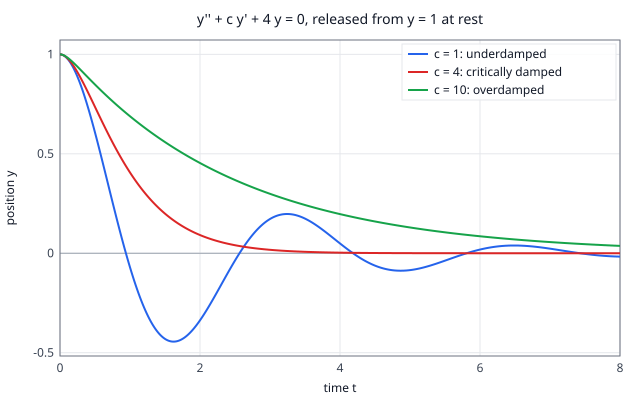

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
y1 = dsolve(y'' + y' + 4*y == 0, y, t, 0, [1, 0]);
y2 = dsolve(y'' + 4*y' + 4*y == 0, y, t, 0, [1, 0]);
y3 = dsolve(y'' + 10*y' + 4*y == 0, y, t, 0, [1, 0]);
p = plot(y1, y2, y3, t, 0, 8);
p = legend(p, "c = 1: underdamped", "c = 4: critically damped", "c = 10: overdamped");
labels(title(p, "y'' + c y' + 4 y = 0, released from y = 1 at rest"), "time t", "position y")

Car suspensions are tuned close to critical damping: a car that bounces is underdamped, one that feels like a brick
is overdamped. The overdamped curve is slow because its root $r = -5 + \sqrt{21} \approx -0.42$ is close to 0.

**Try this.** For which damping $c$ does $y'' + cy' + 9y = 0$ stop oscillating?

## 3. Forcing and undetermined coefficients

Push the undamped spring with a periodic force: $y'' + 4y = \cos t$. The general solution is again
**particular + homogeneous**. For the particular solution, guess the shape of the input: $y_p = A\cos t$. Then
$y_p'' + 4y_p = -A\cos t + 4A\cos t = 3A\cos t$, so $A = 1/3$. Starting at rest:

In [5]:
dsolve(y'' + 4*y == cos(t), y, t, 0, [0, 0])

cos(t)/3-cos(2*t)/3

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

The guesses for common inputs:

| input $F(t)$ | guess for $y_p$ |
|---|---|
| polynomial of degree $n$ | polynomial of degree $n$ |
| $e^{at}$ | $Ae^{at}$ |
| $\cos\omega t$ or $\sin\omega t$ | $A\cos\omega t + B\sin\omega t$ |
| products of these | products of the guesses |

**If the guess solves the homogeneous equation, multiply it by $t$.** That is exactly what happens when the push
matches the natural frequency $\omega = 2$:

In [6]:
dsolve(y'' + 4*y == cos(2*t), y, t, 0, [0, 0])
dsolve(y'' + 4*y == cos(9*t/5), y, t, 0, [0, 0])

t*sin(2*t)/4

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

25*cos(9*t/5)/19-25*cos(2*t)/19

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

At $\omega = 2$ the answer $\tfrac t4\sin 2t$ grows without bound: **resonance**. At $\omega = 1.8$, close to 2, the
two cosines $\cos 1.8t$ and $\cos 2t$ drift in and out of step and produce **beats**: a fast oscillation inside a slow
envelope, since $\cos a - \cos b = 2\sin\frac{a + b}{2}\sin\frac{b - a}{2}$.

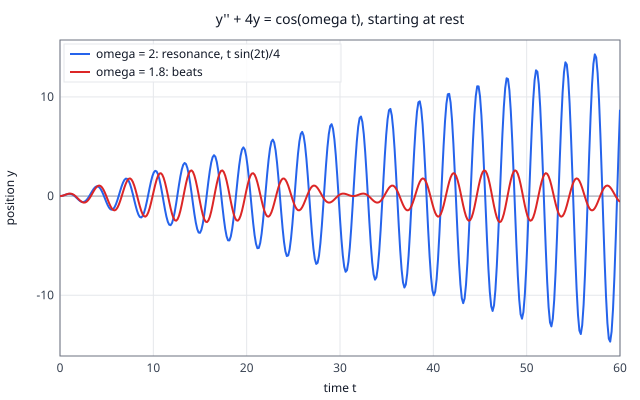

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
p = plot(t*sin(2*t)/4, 25*cos(9*t/5)/19 - 25*cos(2*t)/19, t, 0, 60);
p = legend(p, "omega = 2: resonance, t sin(2t)/4", "omega = 1.8: beats");
labels(title(p, "y'' + 4y = cos(omega t), starting at rest"), "time t", "position y")

**Try this.** Solve $y'' - 3y' + 2y = e^t$. Why does the particular solution contain $te^t$ and not $e^t$?

In [8]:
dsolve(y'' - 3*y' + 2*y == exp(t), y, t)

exp(2*t)*C2+exp(t)*C1-exp(t)*t

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

## 4. The amplitude response

With damping, resonance cannot grow forever. For $y'' + y' + 4y = \cos\omega t$ the steady state is a wave with the
driving frequency $\omega$ and amplitude

$$A(\omega) = \frac{1}{\sqrt{(4 - \omega^2)^2 + \omega^2}},$$

found by putting $y_p = a\cos\omega t + b\sin\omega t$ into the equation. `dsolve` finds the same with $\omega$ left as
a letter:

In [9]:
dsolve(y'' + y' + 4*y == cos(w*t), y, t)

exp(-t/2)*C1*cos(sqrt(15)*t/2)+exp(-t/2)*C2*sin(sqrt(15)*t/2)+(w*sin(t*w)-w^2*cos(t*w)+4*cos(t*w))/(w^4-7*w^2+16)

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

The amplitude is largest where $(4 - \omega^2)^2 + \omega^2$ is smallest:

In [10]:
critical([(4 - w^2)^2 + w^2], [w])
A = 1/sqrt((4 - w^2)^2 + w^2);
eval(subs(A, w, sqrt(14)/2))

[-sqrt(14)/2;
           0;
  sqrt(14)/2]

> Critical points are where every partial derivative is 0 (grad f = 0); Galileo solved 2*w*(2*w^2-7) = 0 and lists the real solutions, one per row. The second-derivative test (classify) says:
>
> - (-sqrt(14)/2): f = 15/4, local minimum
> - (0): f = 16, local maximum
> - (sqrt(14)/2): f = 15/4, local minimum

0.5163977794943223

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The peak is at $\omega = \sqrt{14}/2 \approx 1.87$, a little below the natural frequency 2, with amplitude about
0.52: twice the response to a slow push ($A(0) = 1/4$). With less damping the peak is taller and narrower:

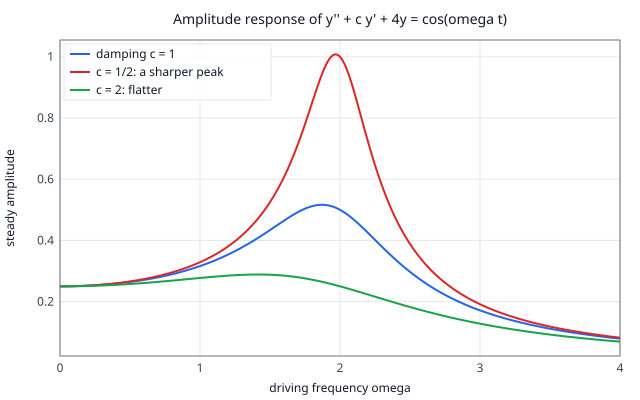

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
p = plot(A, 1/sqrt((4 - w^2)^2 + w^2/4), 1/sqrt((4 - w^2)^2 + 4*w^2), w, 0, 4);
p = legend(p, "damping c = 1", "c = 1/2: a sharper peak", "c = 2: flatter");
labels(title(p, "Amplitude response of y'' + c y' + 4y = cos(omega t)"), "driving frequency omega", "steady amplitude")

This curve is how a radio picks one station: a circuit with little damping responds strongly only near its own
frequency.

**Try this.** For $c = 1/2$, compute the peak height. (Find the minimum of $(4 - \omega^2)^2 + \omega^2/4$.)

## 5. Cauchy–Euler equations

When the coefficients are powers of $x$ matching the derivative, as in $x^2y'' + bxy' + cy = 0$, try $y = x^r$:
$x^2y'' = r(r - 1)x^r$ and $xy' = rx^r$, so $r(r - 1) + br + c = 0$. Example: $x^2y'' - 2xy' + 2y = 0$ gives
$r^2 - 3r + 2 = 0$, so $r = 1, 2$:

In [12]:
dsolve(x^2*y'' - 2*x*y' + 2*y == 0, y, x)
dsolve(x^2*y'' + x*y' + 4*y == 0, y, x)

C1*x+C2*x^2

> Cauchy–Euler equation (the coefficient of y^(k) is a multiple of x^k): try y = x^r, or substitute x = e^u to get constant coefficients. Characteristic polynomial in r: r^2-3*r+2.

C1*cos(2*log(x))+C2*sin(2*log(x))

> Cauchy–Euler equation (the coefficient of y^(k) is a multiple of x^k): try y = x^r, or substitute x = e^u to get constant coefficients. Characteristic polynomial in r: r^2+4.

Complex roots $r = \pm 2i$ give $x^{2i} = e^{2i\log x}$, so $\cos(2\log x)$ and $\sin(2\log x)$. The substitution
$x = e^u$ turns any Cauchy–Euler equation into one with constant coefficients in $u$, which is why the cases match
section 1 with $t$ replaced by $\log x$. These equations appear when you separate variables in polar coordinates
(lesson 8).

**Try this.** Solve $x^2y'' - 3xy' + 4y = 0$. The characteristic equation has a double root; what replaces the
$t e^{rt}$ of section 1?

In [13]:
dsolve(x^2*y'' - 3*x*y' + 4*y == 0, y, x)

x^2*(C1+C2*log(x))

> Cauchy–Euler equation (the coefficient of y^(k) is a multiple of x^k): try y = x^r, or substitute x = e^u to get constant coefficients. Characteristic polynomial in r: r^2-4*r+4.

## Summary

* $ay'' + by' + cy = 0$: roots of $ar^2 + br + c = 0$ give $e^{rt}$, $te^{rt}$, or $e^{\alpha t}\cos\beta t$ and
  $e^{\alpha t}\sin\beta t$.
* Damping $c$ versus $2\sqrt{mk}$: under-, critically and overdamped.
* Undetermined coefficients: guess the shape of the input; multiply by $t$ if the guess solves the homogeneous
  equation.
* Without damping, forcing at the natural frequency gives resonance $t\sin\omega t$; nearby frequencies give beats.
  With damping, the amplitude response has a finite peak just below the natural frequency.
* Cauchy–Euler: try $x^r$.

Next: [Laplace transforms](04-laplace-transforms.ipynb), which handle switched-on forces and hammer blows.

## Exercises

1. **Three cases.** Solve $y'' + 2y' + y = 0$, $y'' + 2y' + 2y = 0$ and $y'' + 2y' - 3y = 0$ with $y(0) = 0$,
   $y'(0) = 1$, and plot them together.
2. **Polynomial forcing.** Solve $y'' + y = t^2$. What is the particular solution?
3. **Pendulum clock.** A small pendulum obeys $\theta'' + (g/L)\theta = 0$. What length gives a period of 2 seconds
   ($g = 9.8$ m/s²)?
4. **LC circuit.** Solve $Lq'' + q/C = 0$ and give the frequency of oscillation.
5. **Resonance peak.** Show that the amplitude $1/\sqrt{(k - \omega^2)^2 + c^2\omega^2}$ of $y'' + cy' + ky =
   \cos\omega t$ has its peak at $\omega^2 = k - c^2/2$ when $c^2 < 2k$.

## Hints and answers

* **Section 1, Try this.** Double root $r = -3$: $y = (1 + 3t)e^{-3t}$. The $t$ supplies the second solution that the
  repeated root does not.
* **Section 2, Try this.** $c^2 - 36 \ge 0$: $c \ge 6$.
* **Section 3, Try this.** $e^t$ already solves $y'' - 3y' + 2y = 0$ (root $r = 1$), so the guess becomes $Ate^t$;
  $A = -1$.
* **Section 4, Try this.** Minimum at $\omega^2 = 4 - 1/8 = 31/8$, where $(1/8)^2 + 31/32 = 63/64$; the peak height
  is $8/\sqrt{63} \approx 1.01$, four times the slow-push response $1/4$.
* **Section 5, Try this.** $r = 2$ twice: $y = x^2(C_1 + C_2\log x)$. $\log x$ plays the role of $t$.
* **Exercise 1.** $te^{-t}$, $e^{-t}\sin t$, $(e^t - e^{-3t})/4$.
* **Exercise 2.** $y_p = t^2 - 2$.
* **Exercise 3.** Period $2\pi\sqrt{L/g} = 2$ gives $L = g/\pi^2 \approx 0.99$ m.
* **Exercise 4.** $q = C_1\cos(t/\sqrt{LC}) + C_2\sin(t/\sqrt{LC})$, angular frequency $1/\sqrt{LC}$.
* **Exercise 5.** Minimize $u = (k - \omega^2)^2 + c^2\omega^2$ in $\omega^2$: $-2(k - \omega^2) + c^2 = 0$.

## Sources

1. W. E. Boyce, R. C. DiPrima and D. B. Meade, *Elementary Differential Equations and Boundary Value Problems*, 11th
   ed., Wiley (2017), chapter 3.
2. K. Y. Billah and R. H. Scanlan, "Resonance, Tacoma Narrows bridge failure, and undergraduate physics textbooks",
   *American Journal of Physics* 59 (1991) 118–124.
3. A. P. French, *Vibrations and Waves*, Norton (1971), chapters 3 and 4.